In [90]:
# Necessary imports
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

from scipy import stats
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

In [91]:
columns = ['AppID', 'Name', 'Release date', 'Estimated owners', 'Peak CCU', 'Required age', 'Price', 'Discount', 'DLC count', 'About the game', 'Supported languages', 'Full audio languages', 'Reviews', 'Header image', 'Website', 'Support url', 'Support email', 'Windows', 'Mac', 'Linux', 'Metacritic score', 'Metacritic url', 'User score', 'Positive', 'Negative', 'Score rank', 'Achievements', 'Recommendations', 'Notes', 'Average playtime forever', 'Average playtime two weeks', 'Median playtime forever', 'Median playtime two weeks', 'Developers', 'Publishers', 'Categories', 'Genres', 'Tags', 'Screenshots', 'Movies']

df = pd.read_csv("games.csv",names=columns, header=0)

In [92]:
df.head()

,AppID,Name,Release date,Estimated owners,Peak CCU,Required age,Price,Discount,DLC count,About the game,...,Average playtime two weeks,Median playtime forever,Median playtime two weeks,Developers,Publishers,Categories,Genres,Tags,Screenshots,Movies
0,2539430,Black Dragon Mage Playtest,"Aug 1, 2023",0 - 0,0,0,0.00,0,0,NaN,...,0,0,0,NaN,NaN,NaN,NaN,NaN,https://shared.akamai.steamstatic.com/store_it...,NaN
1,496350,Supipara - Chapter 1 Spring Has Come!,"Jul 29, 2016",0 - 20000,0,0,5.24,65,0,"Springtime, April: when the cherry trees come ...",...,0,8,0,minori,MangaGamer,"Single-player,Steam Trading Cards,Steam Cloud,...",Adventure,"Adventure,Visual Novel,Anime,Cute",https://shared.akamai.steamstatic.com/store_it...,NaN
2,1034400,Mystery Solitaire The Black Raven,"May 6, 2019",0 - 20000,0,0,4.99,0,0,"Immerse yourself in the most beloved, mystical...",...,0,0,0,Somer Games,8floor,"Single-player,Family Sharing",Casual,"Casual,Card Game,Solitaire,Puzzle,Hidden Objec...",https://shared.akamai.steamstatic.com/store_it...,NaN
3,3292190,버튜버 파라노이아 - Vtuber Paranoia,"Oct 31, 2024",0 - 20000,1,0,8.99,0,1,"synopsis 'Hello, I'm Hiyoro, a new YouTuber!' ...",...,0,0,0,유진게임즈,유진게임즈,"Single-player,Steam Achievements,Family Sharing","Casual,Indie,Simulation",NaN,https://shared.akamai.steamstatic.com/store_it...,NaN
4,3631080,Maze Quest VR,"Apr 24, 2025",0 - 20000,0,0,4.99,0,0,Its not just a Maze; its a Quest! Enter the ca...,...,0,0,0,Reality Expanded LLC,Reality Expanded LLC,"Single-player,VR Only,Steam Leaderboards,Famil...","Action,Early Access",NaN,https://shared.akamai.steamstatic.com/store_it...,NaN


In [93]:
df.columns

Index(['AppID', 'Name', 'Release date', 'Estimated owners', 'Peak CCU',
       'Required age', 'Price', 'Discount', 'DLC count', 'About the game',
       'Supported languages', 'Full audio languages', 'Reviews',
       'Header image', 'Website', 'Support url', 'Support email', 'Windows',
       'Mac', 'Linux', 'Metacritic score', 'Metacritic url', 'User score',
       'Positive', 'Negative', 'Score rank', 'Achievements', 'Recommendations',
       'Notes', 'Average playtime forever', 'Average playtime two weeks',
       'Median playtime forever', 'Median playtime two weeks', 'Developers',
       'Publishers', 'Categories', 'Genres', 'Tags', 'Screenshots', 'Movies'],
      dtype='str')

In [108]:
df['Release date']

0          Aug 1, 2023
1         Jul 29, 2016
2          May 6, 2019
3         Oct 31, 2024
4         Apr 24, 2025
              ...     
125850     Mar 1, 2026
125851    Feb 24, 2026
125852     Mar 1, 2026
125853    Feb 27, 2026
125854     Mar 2, 2026
Name: Release date, Length: 125855, dtype: str

### Data aggregation
For our analysis, we need a dataframe of developers, not of games. For this, let us group all games that share a developer, and look at the count of games released, overall engagement, and average price for each developer.

In [112]:
# Group by developer and aggregate features
developers_df = df.groupby('Developers').agg(
    game_count=('AppID', 'count'), # how many games released
    total_positive=('Positive', 'sum'), # total positive reviews
    total_negative=('Negative', 'sum'), # total negative reviews
    avg_price=('Price', 'mean'), # average game price
    max_success=('Positive', 'max'),
    start_year=('Release date', 'min'),
    end_year=('Release date', 'max')
    # genre_count=('Genres')
).reset_index()

developers_df.head()

,Developers,game_count,total_positive,total_negative,avg_price,max_success,start_year,end_year
0,!CyberApex (SkagoGames),3,2,0,0.723333,1,"Feb 5, 2021","May 24, 2023"
1,!ReTigma Studio,1,2,0,15.000000,2,"Feb 14, 2024","Feb 14, 2024"
2,#12,1,3,0,0.990000,3,"Aug 14, 2019","Aug 14, 2019"
3,#30A6D-S (Kuma),1,8,1,1.240000,8,"May 22, 2025","May 22, 2025"
4,#FF0000,1,42,2,1.990000,42,"Mar 8, 2022","Mar 8, 2022"


In [ ]:
developers_df['engagement'] = developers_df['total_positive'] + developers_df['total_negative']
developers_df['avg_game_success'] =developers_df['engagement'] / developers_df['game_count']

developers_df.head()

In [115]:
developers_df['end_year']

0        May 24, 2023
1        Feb 14, 2024
2        Aug 14, 2019
3        May 22, 2025
4         Mar 8, 2022
             ...     
72854    Sep 14, 2022
72855    May 16, 2021
72856    Mar 26, 2022
72857    Jul 13, 2018
72858    Aug 16, 2023
Name: end_year, Length: 72859, dtype: str

In [118]:
developers_df['end_year'][-1:-4]

Series([], Name: end_year, dtype: str)

In [ ]:
def get_years_active(end, start):
    

In [ ]:
developers_df['years_active'] = int(developers_df['end_year'][-1:-4]) - int(developers_df['start_year'][-1:-4])

TypeError: int() argument must be a string, a bytes-like object or a real number, not 'Series'

In [107]:
copy_copy_df = developers_df.copy()
copy_copy_df = copy_copy_df.sort_values(by='max_success', ascending=False)
copy_copy_df.head()

,Developers,game_count,total_positive,total_negative,avg_price,max_success,engagement,avg_game_success
61807,Valve,35,13776163,1870072,1.508571,7642084,15646235,4.470353e+05
49221,Rockstar North,3,1783559,269966,6.160000,1739980,2053525,6.845083e+05
43400,PUBG Corporation,1,1520457,1037487,0.000000,1520457,2557944,2.557944e+06
47757,Re-Logic,1,1373979,35494,4.990000,1373979,1409473,1.409473e+06
60920,Ubisoft Montreal,28,2727310,544657,3.224643,1172854,3271967,1.168560e+05


## Data Quality

In [24]:
developers_df.isna().sum()

Developers        0
game_count        0
total_positive    0
total_negative    0
avg_price         0
engagement        0
dtype: int64

In [25]:
developers_df.duplicated().sum()

np.int64(0)

## Data Visualization

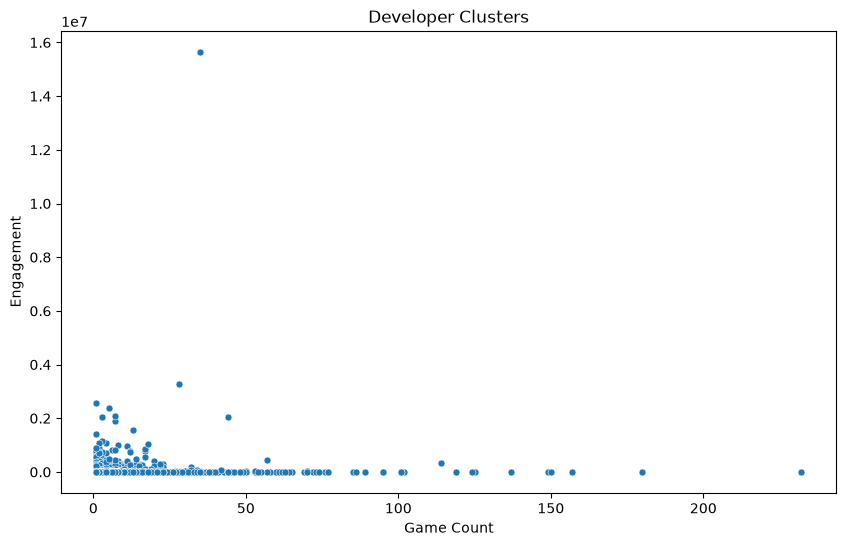

In [26]:
plt.figure(figsize=(10,6))

sns.scatterplot(
    x='game_count',
    y='engagement',
    data=developers_df,
    s=25
)
plt.title('Developer Clusters')
plt.xlabel('Game Count')
plt.ylabel('Engagement')
plt.show()

## Jacob's graphs

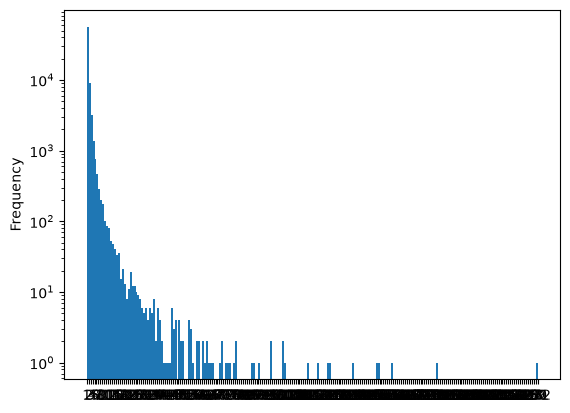

In [27]:
result = df.groupby("Developers").agg(
    positive=("Positive", "sum"),
    count=("Developers", "size")
)
maxX = round(result["count"].max())
result["count"].plot.hist(bins=range(1,maxX+1))
plt.yscale("log")
plt.xticks(range(1,maxX+1));

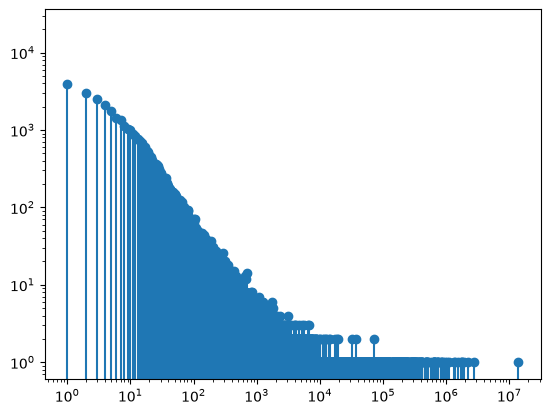

In [28]:
freq = result['positive'].value_counts().sort_index()

plt.stem(freq.index, freq.values)
plt.yscale("log")
plt.xscale("log")

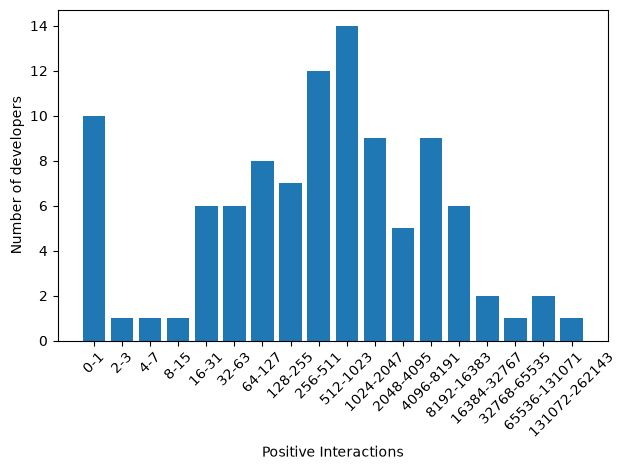

In [29]:
dev_game_four = result[result["count"] == 10]
bins = [0] + [2**i for i in range(1, int(np.ceil(np.log2(dev_game_four["positive"].max() + 1))) + 1)]
counts, edges = np.histogram(dev_game_four["positive"], bins=bins)
plt.bar(
    [f"{int(a)}-{int(b)-1}" for a, b in zip(edges[:-1], edges[1:])],
    counts
)
plt.xlabel("Positive Interactions")
plt.ylabel("Number of developers")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [30]:
dev_game_four.shape

(101, 2)

## Outliers

In [31]:
developers_df.describe()

,game_count,total_positive,total_negative,avg_price,engagement
count,72859.000000,7.285900e+04,7.285900e+04,72859.000000,7.285900e+04
mean,1.611414,1.758784e+03,2.848075e+02,4.857781,2.043591e+03
std,3.124426,5.793022e+04,9.118371e+03,9.637942,6.621155e+04
min,1.000000,0.000000e+00,0.000000e+00,0.000000,0.000000e+00
25%,1.000000,0.000000e+00,0.000000e+00,0.990000,0.000000e+00
50%,1.000000,6.000000e+00,1.000000e+00,2.990000,8.000000e+00
75%,1.000000,4.800000e+01,1.300000e+01,5.990000,6.400000e+01
max,232.000000,1.377616e+07,1.870072e+06,999.980000,1.564624e+07


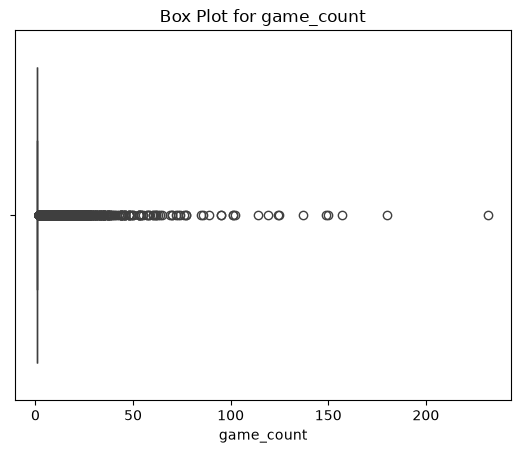

In [32]:
sns.boxplot(x=developers_df['game_count'])
plt.title("Box Plot for game_count")
plt.show()

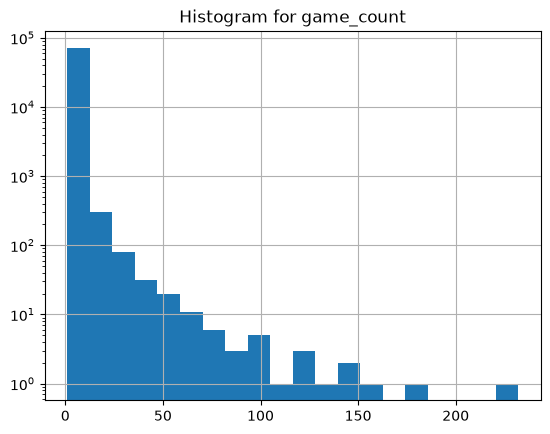

In [33]:
developers_df['game_count'].hist(bins=20, log=True)
plt.title("Histogram for game_count")
plt.show()

In [34]:
developers_df.describe()

,game_count,total_positive,total_negative,avg_price,engagement
count,72859.000000,7.285900e+04,7.285900e+04,72859.000000,7.285900e+04
mean,1.611414,1.758784e+03,2.848075e+02,4.857781,2.043591e+03
std,3.124426,5.793022e+04,9.118371e+03,9.637942,6.621155e+04
min,1.000000,0.000000e+00,0.000000e+00,0.000000,0.000000e+00
25%,1.000000,0.000000e+00,0.000000e+00,0.990000,0.000000e+00
50%,1.000000,6.000000e+00,1.000000e+00,2.990000,8.000000e+00
75%,1.000000,4.800000e+01,1.300000e+01,5.990000,6.400000e+01
max,232.000000,1.377616e+07,1.870072e+06,999.980000,1.564624e+07


In [35]:
z = np.abs(stats.zscore(developers_df['game_count']))
outliers_game_count = developers_df[z > 3]
outliers_game_count.shape

(641, 6)

In [36]:
outliers_game_count.head()

,Developers,game_count,total_positive,total_negative,avg_price,engagement
10,&y,11,36,3,0.445455,39
53,07th Expansion,14,15272,604,8.019286,15876
86,"100 Cozy Games,Cats",41,33,1,0.891220,34
116,10tons Ltd,17,9303,1051,4.210588,10354
164,16air,13,73,13,1.240769,86


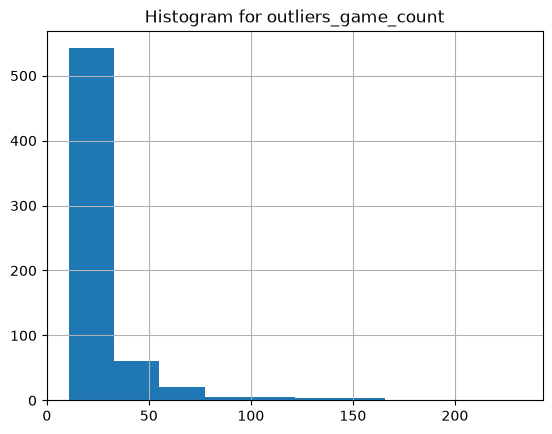

In [37]:
outliers_game_count['game_count'].hist(bins=10)
plt.title("Histogram for outliers_game_count")
plt.show()

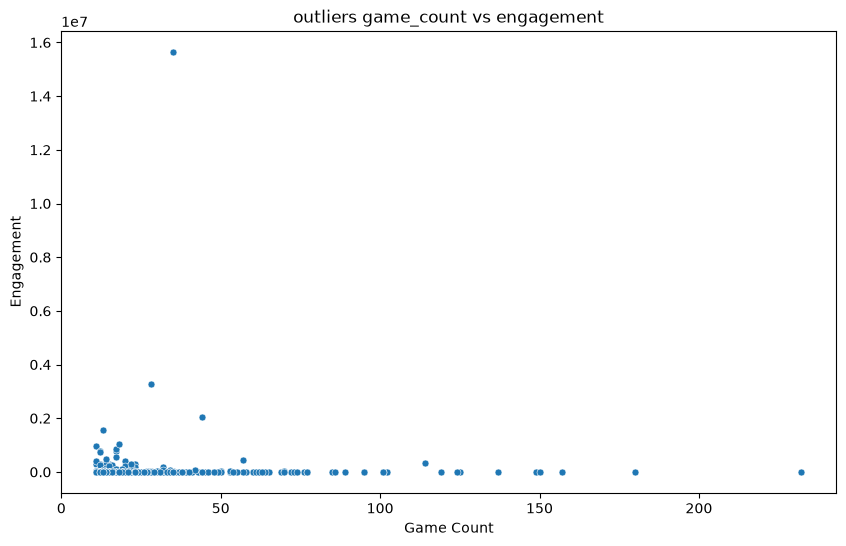

In [38]:
plt.figure(figsize=(10,6))

sns.scatterplot(
    data=outliers_game_count,
    x='game_count',
    y='engagement',
    s=25
)
plt.title('outliers game_count vs engagement')
plt.xlabel('Game Count')
plt.ylabel('Engagement')
plt.show()

In [39]:
z = np.abs(stats.zscore(developers_df['engagement']))
outliers_engagement = developers_df[z > 3]
outliers_engagement.shape


(124, 6)

In [40]:
outliers_engagement.head()

,Developers,game_count,total_positive,total_negative,avg_price,engagement
118,11 bit studios,10,231666,22877,6.131000,254543
301,24 Entertainment,1,225960,98967,0.000000,324927
456,"343 Industries,Splash Damage,Ruffian Games,Bun...",4,223635,18432,2.497500,242067
618,4A Games,4,274022,28356,3.240000,302378
1444,ATLUS,15,292378,18534,18.456667,310912


In [41]:
Q1_game_count = developers_df['game_count'].quantile(0.25)
Q3_game_count = developers_df['game_count'].quantile(0.75)
IQR_game_count = Q3_game_count - Q1_game_count

lower_bound_game_count = Q1_game_count - 1.5 * IQR_game_count
upper_bound_game_count = Q3_game_count + 1.5 * IQR_game_count


outliers_game_count = developers_df[(developers_df['game_count'] < lower_bound_game_count) | (developers_df['game_count'] > upper_bound_game_count)]
outliers_game_count.shape

(16063, 6)

In [42]:
Q1_engagement = developers_df['engagement'].quantile(0.25)
Q3_engagement = developers_df['engagement'].quantile(0.75)
IQR_engagement = Q3_engagement - Q1_engagement

lower_bound_engagement = Q1_engagement - 1.5 * IQR_engagement
upper_bound_engagement = Q3_engagement + 1.5 * IQR_engagement

outliers_engagement = developers_df[(developers_df['engagement'] < lower_bound_engagement) | (developers_df['engagement'] > upper_bound_engagement)]
outliers_engagement

,Developers,game_count,total_positive,total_negative,avg_price,engagement
8,#workshop,3,9127,361,2.350000,9488
18,"+Mpact Games, LLC.",1,172,56,0.000000,228
30,.GRAVITY,1,352,80,17.490000,432
35,//commentout,1,440,49,7.190000,489
38,0 Deer Soft,6,1150,250,2.976667,1400
...,...,...,...,...,...,...
72745,鸽屋谷,1,242,0,2.990000,242
72747,鹊思网络,1,122,118,1.880000,240
72756,黄昏フロンティア,3,2475,323,20.990000,2798
72835,유진게임즈,13,293,31,2.994615,324


In [43]:
outliers_either = developers_df[(developers_df['engagement'] < lower_bound_engagement) | (developers_df['engagement'] > upper_bound_engagement) | (developers_df['game_count'] < lower_bound_game_count) | (developers_df['game_count'] > upper_bound_game_count)]

outliers_either.shape

(22475, 6)

In [44]:
outliers_both = developers_df[((developers_df['engagement'] < lower_bound_engagement) | (developers_df['engagement'] > upper_bound_engagement)) & ((developers_df['game_count'] < lower_bound_game_count) | (developers_df['game_count'] > upper_bound_game_count))]

outliers_both.shape

(6148, 6)

## C. Preprocessing

In [45]:
columns_to_drop = ['Estimated owners', 'Peak CCU', 'Required age', 'Discount', 'Supported languages', 'Full audio languages', 'Reviews', 'Header image', 'Website', 'Support url', 'Support email','Windows', 'Mac', 'Linux', 'Metacritic score', 'Metacritic url', 'User score', 'Score rank', 'Achievements', 'Notes', 'Average playtime forever', 'Average playtime two weeks', 'Median playtime forever', 'Median playtime two weeks', 'Publishers', 'Categories', 'Tags'  ]
essential_attributes_df = df.drop(columns=columns_to_drop)

essential_attributes_df.columns

Index(['AppID', 'Name', 'Release date', 'Price', 'DLC count', 'About the game',
       'Positive', 'Negative', 'Recommendations', 'Developers', 'Genres',
       'Screenshots', 'Movies'],
      dtype='str')

### Removing duplicates
As seen previously, there were no duplicates found in our dataset:

So no cleaning is necessary for this step.

### Processing missing entries

Let's go ahead and remove any entries with a missing developer, as we need to know the developer(s) of the games

In [46]:
essential_attributes_df.shape


(125855, 13)

In [47]:
essential_attributes_df = essential_attributes_df.dropna(subset=['Developers']) 

In [48]:
essential_attributes_df['Developers'].isna().sum()

np.int64(0)

In [49]:
essential_attributes_df['Developers'].isnull().sum()

np.int64(0)

In [50]:
essential_attributes_df.shape


(117406, 13)

## D. Exploratory Data Analysis

## E. Pattern Discovery

In [51]:
essential_attributes_df.shape

(117406, 13)

In [52]:
essential_attributes_df.columns

Index(['AppID', 'Name', 'Release date', 'Price', 'DLC count', 'About the game',
       'Positive', 'Negative', 'Recommendations', 'Developers', 'Genres',
       'Screenshots', 'Movies'],
      dtype='str')

In [53]:
essential_attributes_df.columns

Index(['AppID', 'Name', 'Release date', 'Price', 'DLC count', 'About the game',
       'Positive', 'Negative', 'Recommendations', 'Developers', 'Genres',
       'Screenshots', 'Movies'],
      dtype='str')

### K-Means

To keep our data 2-dimensional, let us only first look at engagement (the sum of positive and negative reviews) and the game count

In [54]:
kmeans_df = developers_df[['game_count', 'engagement']].copy()
kmeans_df = kmeans_df.dropna() # dropping all missing entries for now, later we will revisit this

Scaling our features

In [55]:
scaler = StandardScaler()
kmeans_df_scaled = scaler.fit_transform(kmeans_df)

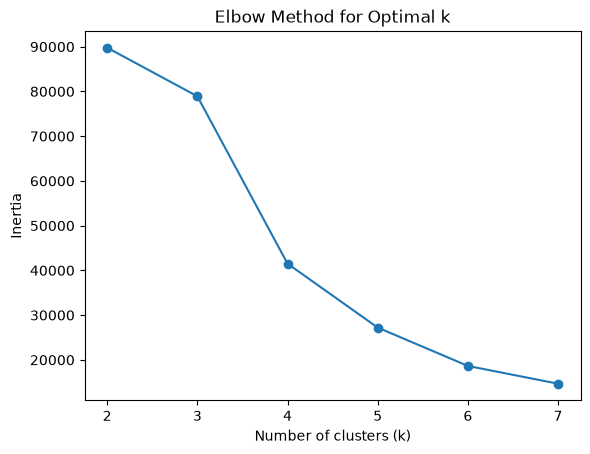

In [56]:
inertia = []
K_range = range(2, 8)
for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init='auto')
    km.fit(kmeans_df_scaled)
    inertia.append(km.inertia_)

plt.plot(K_range, inertia, marker='o')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Inertia')
plt.title('Elbow Method for Optimal k')
plt.show()

For now, let us go with K = 4

In [57]:
# initializing an instance of K-Means
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init='auto'
)

# fitting the model and predicting cluster labels for each row
clusters = kmeans.fit_predict(kmeans_df_scaled)

# adding the cluster labels back to our developers dataframe
developers_df.loc[kmeans_df.index, 'Cluster'] = clusters
developers_df.head()

,Developers,game_count,total_positive,total_negative,avg_price,engagement,Cluster
0,!CyberApex (SkagoGames),3,2,0,0.723333,2,0.0
1,!ReTigma Studio,1,2,0,15.000000,2,0.0
2,#12,1,3,0,0.990000,3,0.0
3,#30A6D-S (Kuma),1,8,1,1.240000,9,0.0
4,#FF0000,1,42,2,1.990000,44,0.0


In [58]:
developers_df.describe()

,game_count,total_positive,total_negative,avg_price,engagement,Cluster
count,72859.000000,7.285900e+04,7.285900e+04,72859.000000,7.285900e+04,72859.000000
mean,1.611414,1.758784e+03,2.848075e+02,4.857781,2.043591e+03,0.006314
std,3.124426,5.793022e+04,9.118371e+03,9.637942,6.621155e+04,0.134044
min,1.000000,0.000000e+00,0.000000e+00,0.000000,0.000000e+00,0.000000
25%,1.000000,0.000000e+00,0.000000e+00,0.990000,0.000000e+00,0.000000
50%,1.000000,6.000000e+00,1.000000e+00,2.990000,8.000000e+00,0.000000
75%,1.000000,4.800000e+01,1.300000e+01,5.990000,6.400000e+01,0.000000
max,232.000000,1.377616e+07,1.870072e+06,999.980000,1.564624e+07,3.000000


In [59]:
cluster_summary = developers_df.groupby('Cluster')[['game_count','engagement']].mean()
print(cluster_summary)

         game_count    engagement
Cluster                          
0.0        1.513206  1.268172e+03
1.0       35.000000  1.564624e+07
2.0        7.545455  1.196065e+06
3.0       54.358779  1.213130e+04


In [60]:
print(developers_df['Cluster'].value_counts())

Cluster
0.0    72694
3.0      131
2.0       33
1.0        1
Name: count, dtype: int64


In [61]:
developers_df.head()

,Developers,game_count,total_positive,total_negative,avg_price,engagement,Cluster
0,!CyberApex (SkagoGames),3,2,0,0.723333,2,0.0
1,!ReTigma Studio,1,2,0,15.000000,2,0.0
2,#12,1,3,0,0.990000,3,0.0
3,#30A6D-S (Kuma),1,8,1,1.240000,9,0.0
4,#FF0000,1,42,2,1.990000,44,0.0


In [62]:
new_df = developers_df[developers_df['Cluster'] != 1.0]
new_df = new_df[['Developers','game_count','engagement', 'Cluster']].copy()

In [63]:
new_df

,Developers,game_count,engagement,Cluster
0,!CyberApex (SkagoGames),3,2,0.0
1,!ReTigma Studio,1,2,0.0
2,#12,1,3,0.0
3,#30A6D-S (Kuma),1,9,0.0
4,#FF0000,1,44,0.0
...,...,...,...,...
72854,𝓛𝓮𝔁𝔂,2,1,0.0
72855,𝕲𝖗𝖆𝖓𝖉𝕸𝖎𝖓𝖎 𝕾𝖙𝖚𝖉𝖎𝖔𝖘 (ᚴᛘᛋ),1,5,0.0
72856,👁️,1,0,0.0
72857,📚瓜山书坊Guashan Bookshop,1,9,0.0


In [64]:
# making a temporary df for the plotting
scaled_plot_df = pd.DataFrame(new_df, columns = ['scaled_game_count', 'scaled_engagement'])
scaled_plot_df['Cluster'] = new_df['Cluster'].values
scaled_plot_df.head()

,scaled_game_count,scaled_engagement,Cluster
0,NaN,NaN,0.0
1,NaN,NaN,0.0
2,NaN,NaN,0.0
3,NaN,NaN,0.0
4,NaN,NaN,0.0


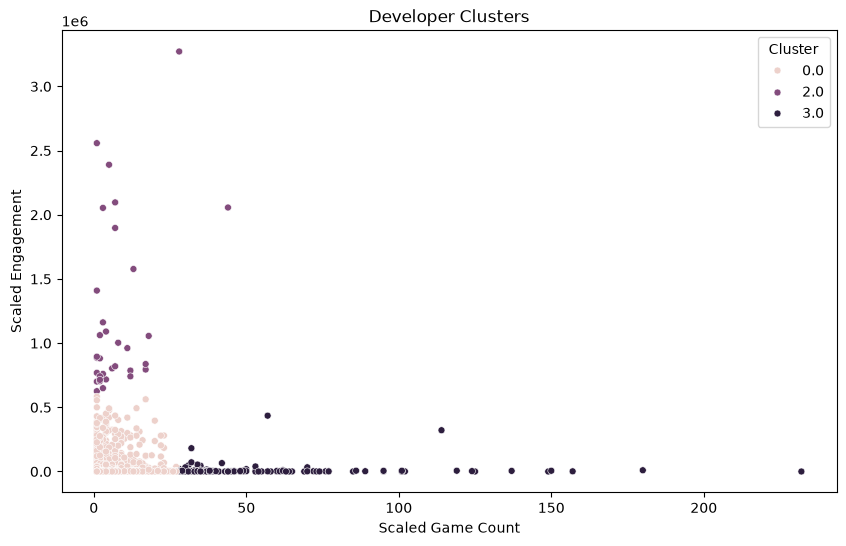

In [65]:

plt.figure(figsize=(10,6))
sns.scatterplot(
    x='game_count',
    y='engagement',
    hue='Cluster',
    data=new_df,
    s=25
)
plt.title('Developer Clusters')
plt.xlabel('Scaled Game Count')
plt.ylabel('Scaled Engagement')
plt.legend(title='Cluster')
plt.show()

In [66]:
interest = new_df[new_df['Cluster'] == 0.0]
interest

,Developers,game_count,engagement,Cluster
0,!CyberApex (SkagoGames),3,2,0.0
1,!ReTigma Studio,1,2,0.0
2,#12,1,3,0.0
3,#30A6D-S (Kuma),1,9,0.0
4,#FF0000,1,44,0.0
...,...,...,...,...
72854,𝓛𝓮𝔁𝔂,2,1,0.0
72855,𝕲𝖗𝖆𝖓𝖉𝕸𝖎𝖓𝖎 𝕾𝖙𝖚𝖉𝖎𝖔𝖘 (ᚴᛘᛋ),1,5,0.0
72856,👁️,1,0,0.0
72857,📚瓜山书坊Guashan Bookshop,1,9,0.0


In [67]:
interest = pd.DataFrame(interest, columns = ['game_count','Engagement'])
interest

,game_count,Engagement
0,3,NaN
1,1,NaN
2,1,NaN
3,1,NaN
4,1,NaN
...,...,...
72854,2,NaN
72855,1,NaN
72856,1,NaN
72857,1,NaN


In [68]:
kmeans_10 = KMeans(
    n_clusters=10,
    random_state=21,
    n_init='auto'
)

interest_df_scaled = scaler.fit_transform(interest)
clusters = kmeans_10.fit_predict(interest_df_scaled)

# adding the cluster labels back to our developers dataframe
interest.loc[interest.index, 'Cluster'] = clusters
interest['log_engagement'] = np.log10(interest['Engagement'])
interest.head()

/home/mango/BSU/fall26/dataMining/finalProject/.venv/lib64/python3.14/site-packages/sklearn/utils/extmath.py:1211: RuntimeWarning: invalid value encountered in divide
  updated_mean = (last_sum + new_sum) / updated_sample_count
/home/mango/BSU/fall26/dataMining/finalProject/.venv/lib64/python3.14/site-packages/sklearn/utils/extmath.py:1216: RuntimeWarning: invalid value encountered in divide
  T = new_sum / new_sample_count
/home/mango/BSU/fall26/dataMining/finalProject/.venv/lib64/python3.14/site-packages/sklearn/utils/extmath.py:1240: RuntimeWarning: invalid value encountered in divide
  new_unnormalized_variance -= correction**2 / new_sample_count


ValueError: Input X contains NaN.
KMeans does not accept missing values encoded as NaN natively. For supervised learning, you might want to consider sklearn.ensemble.HistGradientBoostingClassifier and Regressor which accept missing values encoded as NaNs natively. Alternatively, it is possible to preprocess the data, for instance by using an imputer transformer in a pipeline or drop samples with missing values. See https://scikit-learn.org/stable/modules/impute.html You can find a list of all estimators that handle NaN values at the following page: https://scikit-learn.org/stable/modules/impute.html#estimators-that-handle-nan-values

In [ ]:
developer_df.head()

,Developers,game_count,total_positive,total_negative,avg_price,Engagement,Cluster
0,!CyberApex (SkagoGames),3,2,0,0.723333,2,0.0
1,!ReTigma Studio,1,2,0,15.000000,2,0.0
2,#12,1,3,0,0.990000,3,0.0
3,#30A6D-S (Kuma),1,8,1,1.240000,9,0.0
4,#FF0000,1,42,2,1.990000,44,0.0


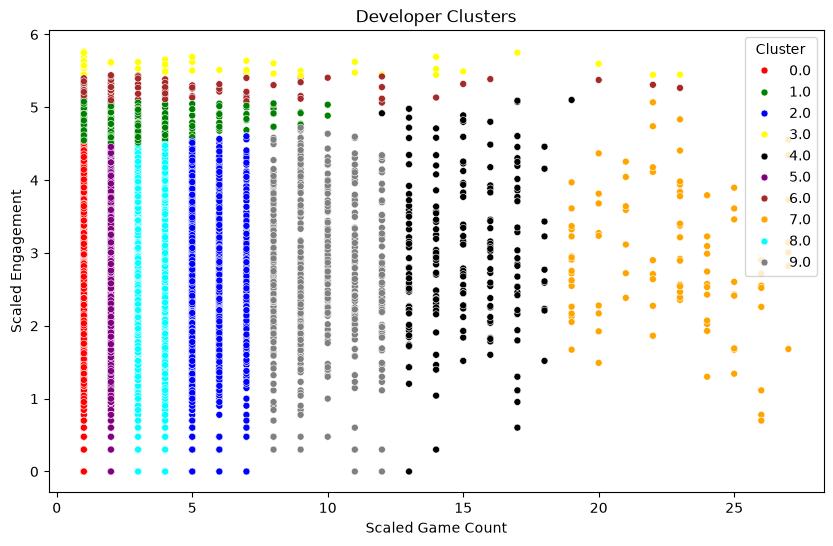

In [ ]:
plt.figure(figsize=(10,6))

colors = ['red','green','blue','yellow','black','purple','brown','orange','cyan', 'grey']

sns.scatterplot(
    x='game_count',
    y='log_engagement',
    hue='Cluster',
    palette=colors,
    data=interest,
    s=25
)
plt.title('Developer Clusters')
plt.xlabel('Scaled Game Count')
plt.ylabel('Scaled Engagement')
plt.legend(title='Cluster')
plt.show()

In [ ]:
print(interest['Cluster'].value_counts())

Cluster
0.0    56599
5.0     8809
8.0     4438
2.0     1435
9.0      607
1.0      327
4.0      214
7.0      108
6.0      103
3.0       54
Name: count, dtype: int64


Now let's take average price also into consideration

In [ ]:
# new df for k-means, but taking avg_price into consideration
kmeans_df_price = developer_df[['game_count', 'Engagement', 'avg_price']].copy()

#applying scaling
kmeans_df_price_scaled = scaler.fit_transform(kmeans_df_price)

# using our k-means algorithm and passing our scaled np array
clusters_price = kmeans.fit_predict(kmeans_df_price_scaled)

# making a  copy of the developers df, but replacing the cluster labels
copy_df = developer_df.copy()
copy_df.loc[kmeans_df_price.index, 'Clusters'] = clusters_price

# turning the scaled np array into a proper dataframe
price_plot_df = pd.DataFrame(kmeans_df_price_scaled, columns = ['scaled_game_count', 'scaled_engagement','scaled_avg_price'])
price_plot_df['Cluster'] = copy_df['Cluster'].values
print(price_plot_df['Cluster'].value_counts())


Cluster
0.0    72694
3.0      131
2.0       33
1.0        1
Name: count, dtype: int64


To easily plot and visualize our clusters, we must apply PCA - Principal Component Analysis - to reduce our dimensionality

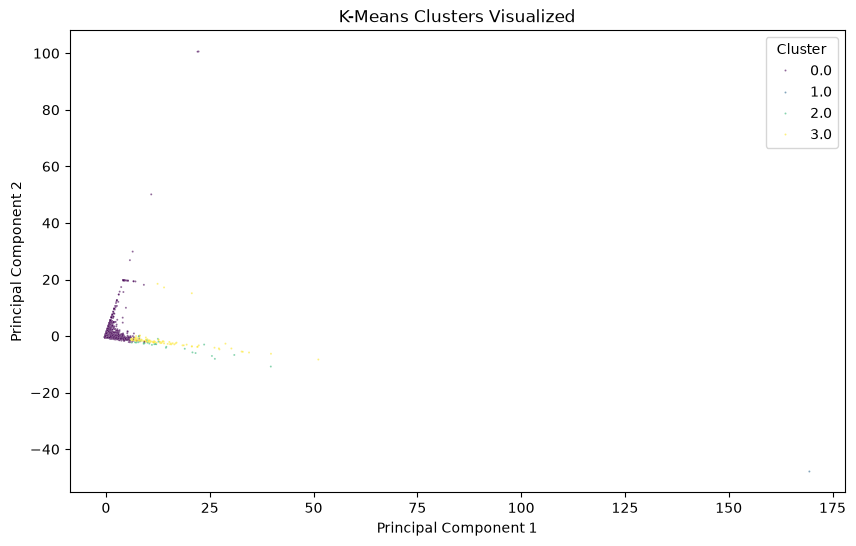

In [ ]:
# reducing the scaled features to 2 dimensions
pca = PCA(n_components=2)
components = pca.fit_transform(kmeans_df_price_scaled)

# creating a temporary dataframe for plotting
plot_df = pd.DataFrame(components, columns=['PC1', 'PC2'])
plot_df['Cluster'] = developer_df.loc[kmeans_df.index, 'Cluster'].values

plt.figure(figsize=(10, 6))
sns.scatterplot(
    x='PC1', y='PC2', 
    hue='Cluster', 
    data=plot_df, 
    palette='viridis', 
    alpha=0.6,
    s=2
)
plt.title('K-Means Clusters Visualized')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(title='Cluster')
plt.show()

Let us try to zoom in a bit, by sampling a bit of this data

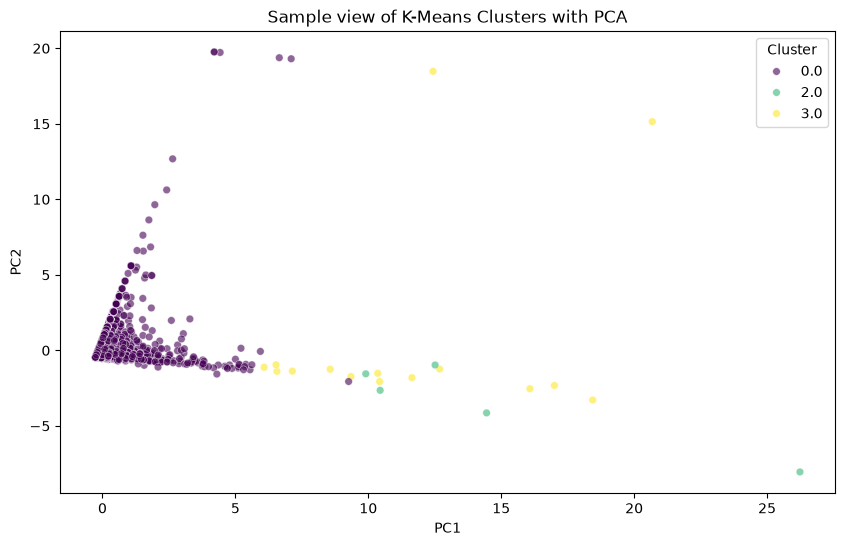

In [ ]:
# sampling 10.000 developers
plot_sample = plot_df.sample(n=10000, random_state=42)

plt.figure(figsize=(10, 6))
sns.scatterplot(
    x='PC1', y='PC2', 
    hue='Cluster', 
    data=plot_sample, 
    palette='viridis', 
    alpha=0.6,
    s=30
)
plt.title('Sample view of K-Means Clusters with PCA')
plt.show()

It looks like we lost one of the clusters, as we saw previously that cluster 1.0 had only one developer

## F. Evaluation

## G. Decision Sensitivity Analysis

## H. Interpretation